# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Vivian Le, Rahil, Yifan
**Date:** 11/04/2026

In [3]:
# Your Phase 1 solution to the problem goes here.

# 1

import pickle
import numpy as np
import matplotlib.pyplot as plt

with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

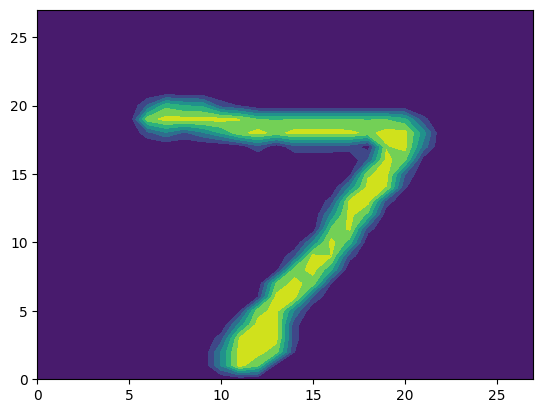

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

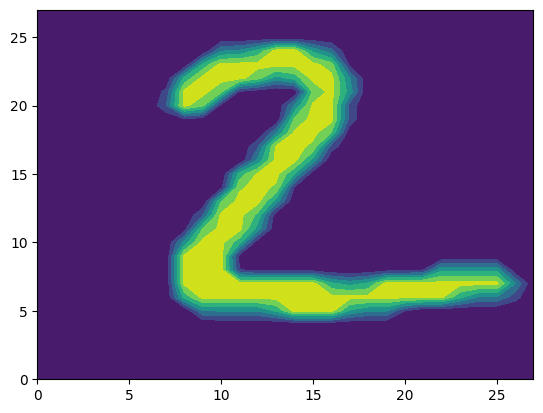

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

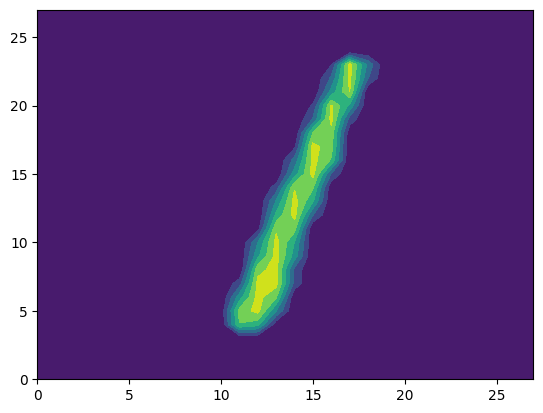

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

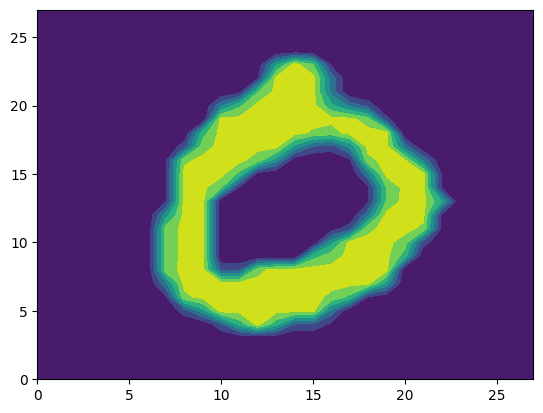

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

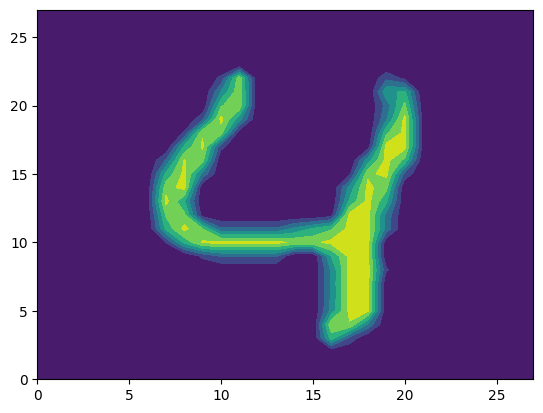

In [4]:
np.set_printoptions(linewidth=120)
for i in range(5):
    print(y_test[i], '\n')
    print(X_test[i], '\n')
    plt.contourf(np.rot90(X_test[i].transpose()))
    plt.show()

In [5]:
#2

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("X_train[i] shape:", X_train[0].shape)
print("X_test[i] shape:", X_test[0].shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (60000, 28, 28)
X_test shape: (10000, 28, 28)
X_train[i] shape: (28, 28)
X_test[i] shape: (28, 28)
y_train shape: (60000,)
y_test shape: (10000,)


Question 2:

(60000, 28, 28) are the dimensions of X_train. This shows 60,000 handwritten digits. In addition, each of them is a 28 by 28 grid of pixels. Moreover, X_test follows the same layout; however, the difference is that it is on a smaller scale, with dimensions of (10000, 28, 28). This gives 10,000 images of 28 by 28 again. In one image, X_train[i] or X_test[i], there are dimensions of (28, 28). This means each digit is a 28x28 matrix using 784 pixels in total, ranging from 0 to 255, respectively blank and dark ink. Label vectors y_train and y_test also have dimensions of (60000,) and (10000,), with one digit label from 0 to 9 for each image.

In [6]:

X = np.zeros((X_train.shape[0], 784))
for i in range(X_train.shape[0]):
    X[i] = X_train[i].reshape((1, 784))

X_te = np.zeros((X_test.shape[0], 784))
for i in range(X_test.shape[0]):
    X_te[i] = X_test[i].reshape((1, 784))

print("X shape:", X.shape)
print("X_te shape:", X_te.shape)

X shape: (60000, 784)
X_te shape: (10000, 784)


In [8]:
#4

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(X, y_train, test_size=10000, random_state=0)

for k in [1, 3, 5, 7, 9]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_tr, y_tr)
    print("k =", k, " validation accuracy:", model.score(X_val, y_val))

k = 1  validation accuracy: 0.974
k = 3  validation accuracy: 0.9741
k = 5  validation accuracy: 0.9713
k = 7  validation accuracy: 0.9714
k = 9  validation accuracy: 0.9693


We picked k by holding out 10,000 of the training images as a validation set, fitting on the other 50,000, and comparing accuracy for several values of k. We did not tune k on the test set, because then the test accuracy in #5 would be biased upward.

The optimal number of neighbors is k = 3 (97.41% validation accuracy). k = 1 is basically tied (97.40%), and accuracy drops slowly as k grows past 3. With large k the vote starts to pull in images from similar-looking digits, such as a 4 near some 9s.

Test accuracy: 0.9705


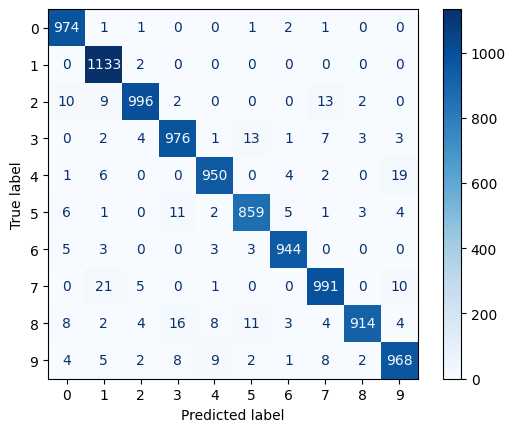

In [10]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X, y_train)
y_pred = model.predict(X_te)

print("Test accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot(cmap='Blues')
plt.show()

Using k = 3 and training on all 60,000 training images, the classifier gets 97.05% accuracy on the test set, which is 295 mistakes out of 10,000. That is close to the 97.41% validation accuracy, so the choice of k held up on new data. In the confusion matrix, rows are the true digit and columns are the predicted digit, and almost every count sits on the diagonal, where the predictions are correct. The easiest digits were 1 (1133 of 1135 correct) and 0 (974 of 980): a 1 is one vertical stroke and a 0 is a ring, and few other digits put ink in those same pixels. The hardest digit was 8, at about 94% (914 of 974), because it shares curves with 3, 5, 9 and 0. The most common mistakes were 7 predicted as 1 (21 times), 4 as 9 (19), 8 as 3 (16), 3 as 5 (13) and 2 as 7 (13), all pairs that look alike in handwriting. These errors happen because kNN only compares raw pixel values by distance and knows nothing about strokes or shapes, so a slanted, thick or off-center digit can end up closer to the wrong class.

In [ ]:
#6.
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)   

pairs = []
for i in range(10):
    for j in range(10):
        if cm_off[i, j] > 0:
            pairs.append((cm_off[i, j], i, j))
pairs.sort(reverse=True)

for count, true, pred in pairs[:10]:
    print(f"true {true} -> predicted {pred}: {count}")

true 7 -> predicted 1: 21
true 4 -> predicted 9: 19
true 8 -> predicted 3: 16
true 3 -> predicted 5: 13
true 2 -> predicted 7: 13
true 8 -> predicted 5: 11
true 5 -> predicted 3: 11
true 7 -> predicted 9: 10
true 2 -> predicted 0: 10
true 9 -> predicted 4: 9


The most common mistakes were 7 predicted as 1 (21), 4 as 9 (19), 8 as 3 (16), 3 as 5 (13) and 2 as 7 (13). Each pair shares a shape: a closed-top 4 looks like a 9, a 7 with a short top bar is mostly a vertical line like a 1, and 3, 5 and 8 share curved strokes. Many mistakes only go one way. 7 → 1 happened 21 times but 1 → 7 never did, 4 → 9 happened 19 times vs. 9 → 4 9 times, and 8 → 3 happened 16 times vs. 3 → 8 3 times. This is because kNN compares pixel overlap: a thin 7 or 2 sits close to 1s, but a 1 has too little ink to look like a 7. So 1 takes in errors (from 7, 2 and 4) but is almost never misread, while 8 makes the most errors (60), spread across 3, 5, 0 and 4. The mistakes aren’t random; they track shared shapes. Many also come from slanted or off-center digits, since raw-pixel kNN can’t tell that a shifted digit is still the same digit.

7. A color photo is a grid of pixels where each pixel has three values, red, green and blue (RGB), each from 0 to 255. For example, red is (255, 0, 0) and white is (255, 255, 255). An H × W photo becomes three H × W matrices, one per channel, stacked into an H × W × 3 array. Following the hint, you could instead pack each pixel into one number, 65536·R + 256·G + B, which gives a single H × W matrix. That works poorly for kNN, though: a change of 1 in blue changes the value by 1, while a change of 1 in red changes it by 65,536, so similar colors can end up far apart. Separate channels are better. To make the photos tabular, resize them all to the same size, such as 64 × 64. Then flatten each photo into one row of 64 × 64 × 3 = 12,288 values, the same way each 28 × 28 digit became a row of 784, with one column for each pixel’s red, green and blue value. Stacking one row per photo gives an N × 12,288 table plus a label for each photo (such as “cat” or “dog”), which can go straight into a model like kNN. Dividing every value by 255 scales the values to between 0 and 1.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

Prompt 1:
Review our Phase 1 MNIST kNN classification solution. Suggest 2–3 simple improvements to make the code clearer and the analysis more informative without changing the overall approach.

Prompt 2:
Provide revised Python code implementing these improvements while keeping k = 3 and the original training and testing data.

### *AI-proposed changes


1. Replace the for loops used to flatten images with NumPy's reshape() method to make the code shorter and more efficient.
2. Add a calculation of accuracy for each digit using the confusion matrix to better understand which digits are harder to classify.
3. Improve the explanation of kNN's limitations by discussing how differences in handwriting and pixel positions can cause classification errors.

### *Evaluation of AI suggestions


Change	Decision	Reason and verification
1. Simplify reshaping	Accept	The new code is shorter and produces the same array shapes as the original loops.
2. Per-digit accuracy	Accept	This provides more detail about model performance and can be verified using the confusion matrix.
3. Explain limitations	Accept	This helps explain why similar-looking handwritten digits are sometimes misclassified.

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:

import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Load data
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)

X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

# Question 1: Visualize the first five images
for i in range(5):
    print("Digit:", y_test[i])
    print(X_test[i])
    plt.contourf(np.rot90(X_test[i].transpose()))
    plt.show()

# Question 2: Check shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Single image:", X_train[0].shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Question 3: Flatten images (AI improvement 1)
X = X_train.reshape(-1, 784)
X_te = X_test.reshape(-1, 784)

print("Reshaped training:", X.shape)
print("Reshaped testing:", X_te.shape)

# Question 4: Select k using validation data
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y_train, test_size=10000, random_state=0
)

for k in [1, 3, 5, 7, 9]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_tr, y_tr)
    print("k =", k, "validation accuracy:", model.score(X_val, y_val))

# Question 5: Test the selected model
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X, y_train)
y_pred = model.predict(X_te)

print("Test accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm).plot(cmap='Blues')
plt.show()

# AI improvement 2: Accuracy for each digit
digit_accuracy = cm.diagonal() / cm.sum(axis=1)

for digit, acc in enumerate(digit_accuracy):
    print(f"Digit {digit}: {acc:.2%}")

# Question 6: Most common classification mistakes
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

pairs = []
for i in range(10):
    for j in range(10):
        if cm_off[i, j] > 0:
            pairs.append((cm_off[i, j], i, j))

pairs.sort(reverse=True)

for count, true, pred in pairs[:10]:
    print(f"True {true} -> Predicted {pred}: {count}")



In [ ]:
Questions 2–3: Data Shapes and Reshaping
The training set contains 60,000 images and the test set contains 10,000 images. Each image is a 28 × 28 matrix with 784 pixels. The label arrays have shapes (60000,) and (10000,). We flattened the images into 784 features each, producing training and testing matrices of shapes (60000, 784) and (10000, 784). Using reshape() directly makes the code simpler.

Question 4: Choosing k
We tested k = 1, 3, 5, 7, and 9 using a validation set of 10,000 images. The highest validation accuracy was 97.41% at k = 3, so we selected k = 3 for the final model.

Question 5: Model Performance
With k = 3, the model achieved 97.05% test accuracy, correctly classifying 9,705 out of 10,000 images. Most predictions appear along the diagonal of the confusion matrix, indicating correct classifications. Digit 1 was one of the easiest to classify, while digit 8 was more difficult.

Question 6: Classification Errors
The most common mistakes included 7 being predicted as 1, 4 as 9, and 8 as 3. These digits share similar handwritten shapes. Since kNN compares raw pixel distances, changes in handwriting style, position, or stroke thickness can cause errors even when the digits are recognizable to humans.

Question 7: RGB Images
A color image can be represented as an H × W × 3 array, where each pixel contains red, green, and blue values between 0 and 255. For example, a 64 × 64 color image can be flattened into 12,288 features. Each image becomes one row in a dataset, allowing classification models such as kNN to process color images. RGB channels should remain separate because combining them into one number can distort distance calculations.

### *Reflection on AI assistance
In your own words without generative AI.

AI helped us improve our code by suggesting a simpler way to reshape the images and adding per-digit accuracy calculations. These changes made our solution easier to read and helped us better understand the model's mistakes. We also learned that kNN can struggle with different handwriting styles because it relies on pixel distances. Overall, AI was useful for improving our existing work, but we still needed to review the suggestions and verify the results ourselves.